 # Project 17 — Student A: Churn Score Model
**Sub-task:** Fix dtype bug → encode categoricals → train models → tune threshold for max recall on churners → export for the Churn Score API.

Dataset: `clean.csv` (300,000 rows, already cleaned). No missing values, no dtype issues found — verified below.

> Note: this file's columns don't match the `blastchar/telco-customer-churn` Kaggle set named in the brief (that one has 7,043 rows and a `TotalCharges` string bug). If your team needs that exact dataset, swap the load path in the Load Data cell — the rest of the workflow is identical regardless of column names.

**Workflow:** all imports → load/clean/encode → train every model → compare on Accuracy / Precision / Recall / F1 / ROC-AUC / Confusion Matrix → tune threshold on the best model → export for the API.

In [21]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report, precision_recall_curve, average_precision_score)

import xgboost as xgb
import joblib

pd.set_option('display.max_columns', 100)
plt.style.use('seaborn-v0_8-darkgrid')


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


## 2. Load data + fix dtype bug

In [22]:
df = pd.read_csv('/kaggle/input/datasets/shreyy45/churn-dataset/clean.csv')   
df.head()


,Gender,Age,MaritalStatus,Dependents,Occupation,IncomeGroup,Education,Region,CityType,ContractType,PlanType,InternetType,VoicePlan,SMSPlan,OTTSubscription,InternationalCalling,FamilyPlan,Tenure_Months,MonthlyCharges,MonthlyCallMinutes,MonthlySMS,MonthlyDataUsageGB,PeakHourUsagePct,RoamingUsageMinutes,InternationalCallsCount,NightUsagePct,WeekendUsagePct,AvgSessionDurationMin,ActiveDaysPerMonth,PaymentMethod,AutoPay,LatePaymentsCount,OutstandingBalance,DiscountReceivedPct,RechargeFrequency,LastRechargeAmount,PaymentDelayDays,BillingComplaintsCount,NumComplaints,ComplaintResolutionTimeHrs,CustomerSatisfactionScore,SupportCallsCount,TicketEscalationsCount,AvgSignalStrengthPct,CallDropRatePct,NetworkDowntimeHrs,AvgInternetSpeedMbps,CoverageRating,MobileAppSessionsPerMonth,WebsiteLoginFrequency,LoyaltyProgramMember,RewardPoints,ReferralCount,MarketingEmailOpenRatePct,PromotionAcceptance,Churn
0,Female,55,Divorced,0,Salaried,Lower-Mid,Diploma,South,Urban,Month-to-Month,Prepaid,5G,Yes,No,No,Yes,No,4,59.64,340.2,48.0,9.50,43.9,4,12,23.4,24.9,14.6,14,Cash,No,0,0.00,15.5,3,57.51,0,0,1,36.4,1.0,3,1,41.2,9.06,4.7,39.9,1,11,9,No,23.0,1,22.4,Yes,No
1,Female,31,Single,0,Salaried,Low,High School,South,Suburban,Two Year,Prepaid,DSL,No,No,No,No,No,64,30.19,288.2,42.0,15.63,55.5,5,1,26.4,30.8,18.6,24,UPI,No,0,295.86,5.2,4,38.56,1,0,1,1.0,5.0,0,0,100.0,0.00,0.0,105.1,5,10,10,Yes,750.0,1,20.6,Yes,No
2,Male,55,Single,0,Salaried,Lower-Mid,Bachelor,North,Urban,Month-to-Month,Prepaid,5G,Yes,Yes,Yes,No,No,15,51.11,134.0,25.0,0.10,29.3,3,0,7.8,30.2,9.8,8,Credit Card,Yes,0,260.12,7.2,6,60.83,0,0,0,28.2,3.0,2,0,84.9,4.85,4.9,41.7,2,7,5,Yes,971.0,0,25.0,No,No
3,Male,28,Divorced,0,Salaried,Upper-Mid,Diploma,North,Urban,One Year,Postpaid,5G,No,Yes,No,No,No,2,47.35,234.5,28.0,4.58,33.7,2,0,12.7,31.3,17.9,13,UPI,No,0,0.00,16.5,1,35.66,0,0,3,19.0,2.0,1,0,69.6,8.73,2.2,30.7,1,18,6,No,39.0,0,29.2,No,No
4,Male,39,Single,1,Salaried,Lower-Mid,Bachelor,Central,Urban,Two Year,Prepaid,Fiber,Yes,No,No,No,No,0,36.70,247.4,65.0,11.75,39.3,2,0,26.4,43.9,9.7,10,Credit Card,Yes,0,54.70,8.5,5,46.61,0,0,2,40.7,2.0,3,0,63.2,9.69,3.8,55.9,3,13,8,No,18.0,0,16.5,Yes,No


In [23]:
# dtype + null check — this is the "fix raw dtype bug" step.
# On the blastchar dataset TotalCharges loads as object due to blank strings;
# here we just verify nothing similar slipped through.
print(df.dtypes.value_counts())
print("\nNulls per column (only showing >0):")
nulls = df.isnull().sum()
print(nulls[nulls > 0] if nulls.sum() else "No nulls found.")

for c in df.columns:
    if df[c].dtype == 'object':
        coerced = pd.to_numeric(df[c], errors='coerce')
        if coerced.notna().sum() / len(df) > 0.95 and c != 'Churn':
            print(f"'{c}' looks numeric but is stored as text — coercing.")
            df[c] = coerced.fillna(coerced.median())


object     20
float64    19
int64      17
Name: count, dtype: int64

Nulls per column (only showing >0):
No nulls found.


## 3. Target + quick EDA

Churn
0    220621
1     79379
Name: count, dtype: int64
Churn rate: 26.46%


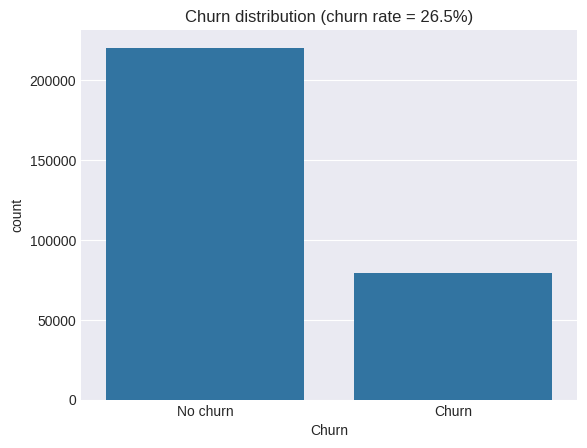

In [24]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

churn_rate = df['Churn'].mean()
print(df['Churn'].value_counts())
print(f"Churn rate: {churn_rate:.2%}")

sns.countplot(x=df['Churn'])
plt.title(f"Churn distribution (churn rate = {churn_rate:.1%})")
plt.xticks([0, 1], ['No churn', 'Churn'])
plt.show()


Class imbalance (~27% positive class) is why every model below uses `class_weight='balanced'` / `scale_pos_weight`, and why the default 0.5 threshold gets revisited later.

## 4. Encode categoricals

In [25]:
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
cat_cols.remove('Churn') if 'Churn' in cat_cols else None
num_cols = [c for c in df.columns if c not in cat_cols + ['Churn']]

print(f"{len(cat_cols)} categorical columns:", cat_cols)
print(f"{len(num_cols)} numeric columns")

df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print("Shape after encoding:", df_enc.shape)

X = df_enc.drop(columns=['Churn'])
y = df_enc['Churn']


19 categorical columns: ['Gender', 'MaritalStatus', 'Occupation', 'IncomeGroup', 'Education', 'Region', 'CityType', 'ContractType', 'PlanType', 'InternetType', 'VoicePlan', 'SMSPlan', 'OTTSubscription', 'InternationalCalling', 'FamilyPlan', 'PaymentMethod', 'AutoPay', 'LoyaltyProgramMember', 'PromotionAcceptance']
36 numeric columns
Shape after encoding: (300000, 79)


## 5. Train/test split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train churn rate:", y_train.mean().round(3), "| Test churn rate:", y_test.mean().round(3))

# Scaled versions — needed for Logistic Regression, Linear SVM, Naive Bayes
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos


Train: (240000, 78) | Test: (60000, 78)
Train churn rate: 0.265 | Test churn rate: 0.265


## 6. Train every model
Required by the brief: **Logistic Regression** and **XGBoost**. Added for a fuller comparison: **Decision Tree, Random Forest, HistGradientBoosting, Linear SVM, Naive Bayes**.

Skipped: RBF-kernel SVC and KNN — both scale badly past ~50k rows and would take 10+ minutes each on 240k training rows.

In [27]:
models = {}   # name -> fitted estimator
probs = {}    # name -> predicted probability / decision score on X_test
preds = {}    # name -> predicted class on X_test (default threshold)
train_times = {}

def train_and_track(name, fit_fn, predict_proba_fn, predict_fn):
    t0 = time.time()
    model = fit_fn()
    train_times[name] = time.time() - t0
    models[name] = model
    probs[name] = predict_proba_fn(model)
    preds[name] = predict_fn(model)
    print(f"{name:22s} trained in {train_times[name]:.1f}s")

train_and_track(
    'Logistic Regression',
    lambda: LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42).fit(X_train_scaled, y_train),
    lambda m: m.predict_proba(X_test_scaled)[:, 1],
    lambda m: m.predict(X_test_scaled)
)

train_and_track(
    'XGBoost',
    lambda: xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8,
                               colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
                               eval_metric='logloss', random_state=42, n_jobs=-1).fit(X_train, y_train),
    lambda m: m.predict_proba(X_test)[:, 1],
    lambda m: m.predict(X_test)
)

train_and_track(
    'Decision Tree',
    lambda: DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=42).fit(X_train, y_train),
    lambda m: m.predict_proba(X_test)[:, 1],
    lambda m: m.predict(X_test)
)

train_and_track(
    'Random Forest',
    lambda: RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced',
                                    n_jobs=-1, random_state=42).fit(X_train, y_train),
    lambda m: m.predict_proba(X_test)[:, 1],
    lambda m: m.predict(X_test)
)

train_and_track(
    'HistGradientBoosting',
    lambda: HistGradientBoostingClassifier(max_iter=300, random_state=42).fit(X_train, y_train),
    lambda m: m.predict_proba(X_test)[:, 1],
    lambda m: m.predict(X_test)
)

train_and_track(
    'Linear SVM',
    lambda: LinearSVC(class_weight='balanced', max_iter=2000, random_state=42).fit(X_train_scaled, y_train),
    lambda m: m.decision_function(X_test_scaled),   # no predict_proba — use decision score for AUC
    lambda m: m.predict(X_test_scaled)
)

train_and_track(
    'Naive Bayes',
    lambda: GaussianNB().fit(X_train_scaled, y_train),
    lambda m: m.predict_proba(X_test_scaled)[:, 1],
    lambda m: m.predict(X_test_scaled)
)


Logistic Regression    trained in 1.3s
XGBoost                trained in 6.5s
Decision Tree          trained in 4.9s
Random Forest          trained in 35.3s
HistGradientBoosting   trained in 6.3s
Linear SVM             trained in 4.6s
Naive Bayes            trained in 0.2s


Random Forest          trained in 89.7s


HistGradientBoosting   trained in 11.8s


Linear SVM             trained in 5.3s


Naive Bayes            trained in 0.3s


## 7. Compare all models — Accuracy, Precision, Recall, F1, ROC-AUC

In [28]:
rows = []
for name in models:
    rows.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, preds[name]), 4),
        'Precision': round(precision_score(y_test, preds[name]), 4),
        'Recall': round(recall_score(y_test, preds[name]), 4),
        'F1 Score': round(f1_score(y_test, preds[name]), 4),
        'ROC-AUC': round(roc_auc_score(y_test, probs[name]), 4),
        'Train time (s)': round(train_times[name], 1)
    })

comparison_df = pd.DataFrame(rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
comparison_df


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Train time (s)
0,Logistic Regression,0.7043,0.4627,0.7292,0.5661,0.7846,1.3
1,Linear SVM,0.7024,0.4609,0.7340,0.5662,0.7846,4.6
2,XGBoost,0.7028,0.4610,0.7272,0.5643,0.7831,6.5
3,HistGradientBoosting,0.7721,0.6214,0.3546,0.4515,0.7825,6.3
4,Random Forest,0.7171,0.4756,0.6738,0.5576,0.7771,35.3
5,Decision Tree,0.6872,0.4422,0.6963,0.5409,0.7538,4.9
6,Naive Bayes,0.7128,0.4674,0.6115,0.5298,0.7509,0.2


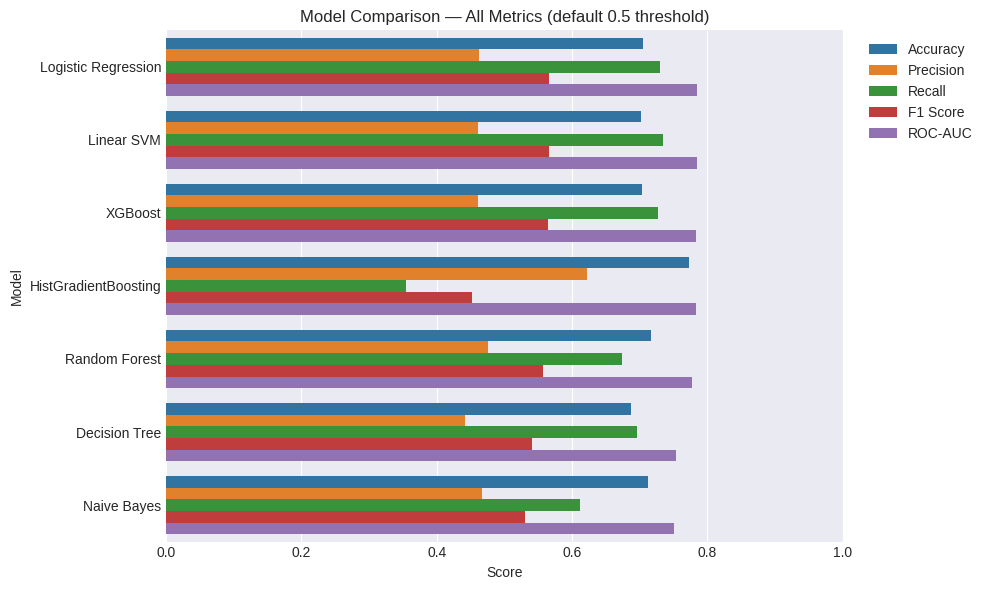

In [29]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
plot_df = comparison_df.melt(id_vars='Model', value_vars=metrics_to_plot, var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_df, x='Score', y='Model', hue='Metric')
plt.xlim(0, 1)
plt.title('Model Comparison — All Metrics (default 0.5 threshold)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 8. Confusion matrix — every model

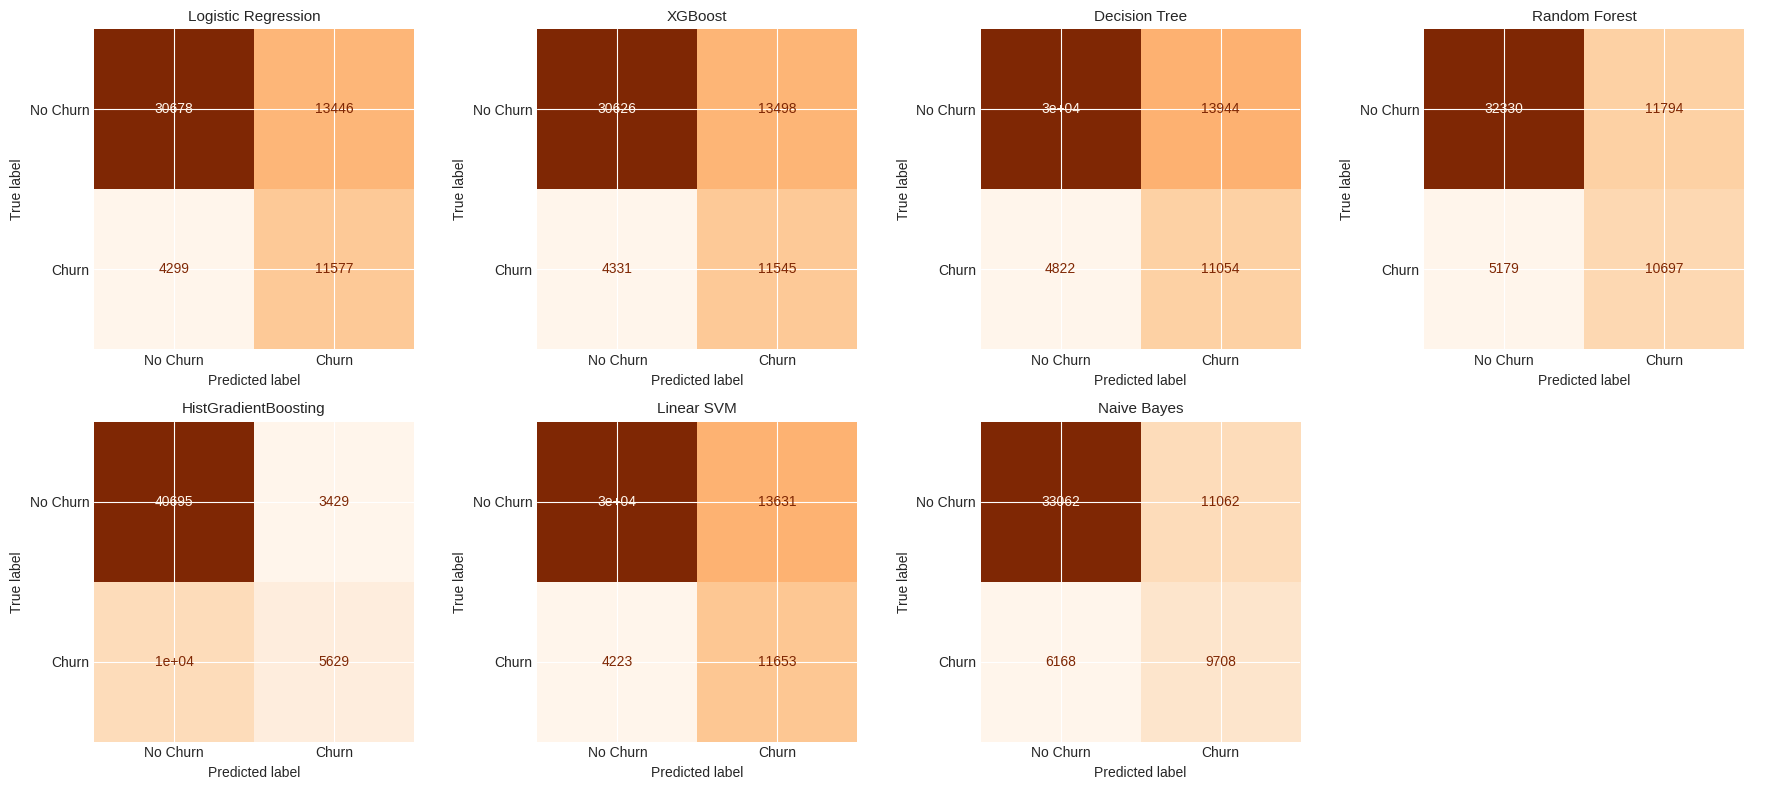

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    disp = ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=ax, cmap='Oranges', colorbar=False)
    ax.set_title(name, fontsize=11)

for ax in axes[len(models):]:
    ax.axis('off')

plt.tight_layout()
plt.show()


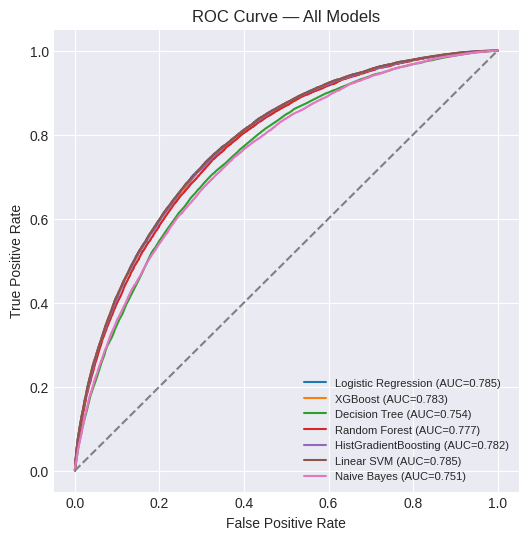

In [31]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = roc_auc_score(y_test, probs[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve — All Models')
ax.legend(fontsize=8)
plt.show()


**Takeaway:** everything clusters near ROC-AUC ~0.78 — this dataset's churn signal is mostly linear, so simple models (Logistic Regression, Linear SVM) keep pace with the ensembles. Naive Bayes and the single Decision Tree trail behind.

**XGBoost is carried forward** for threshold tuning below — it's top-tier on AUC *and* gives per-customer SHAP attributions (Student C builds the retention-driver explanations on top of this), which a Linear SVM or plain Logistic Regression can't offer.

## 9. Threshold tuning for maximum recall on churners

Just cranking the threshold to 0 gives "100% recall" trivially (everyone flagged as a churner) — useless for a retention team. The real goal: **catch as many churners as possible while keeping precision usable enough that Student D's retention-email generator isn't spammed with false alarms.**

Two views below:
- **F2-score optimum** — weights recall 2x more than precision, still keeps precision from collapsing.
- **Recall-target table** — pick a fixed recall (e.g. 90%) and read off the precision cost. This is usually what "maximum recall" means in a churn-ops context.

In [32]:
xgb_clf = models['XGBoost']
xgb_probs = probs['XGBoost']

precisions, recalls, thresholds = precision_recall_curve(y_test, xgb_probs)

beta = 2
f2_scores = (1 + beta**2) * (precisions * recalls) / (beta**2 * precisions + recalls + 1e-9)
best_idx = np.argmax(f2_scores[:-1])
best_threshold_f2 = thresholds[best_idx]

print(f"Best F2 threshold: {best_threshold_f2:.3f}")
print(f"  Precision: {precisions[best_idx]:.3f}")
print(f"  Recall:    {recalls[best_idx]:.3f}")
print(f"  F2 score:  {f2_scores[best_idx]:.3f}")


Best F2 threshold: 0.294
  Precision: 0.361
  Recall:    0.915
  F2 score:  0.701


In [33]:
targets = [0.80, 0.85, 0.90, 0.95]
rows = []
for target in targets:
    valid_idx = np.where(recalls >= target)[0]
    idx = valid_idx[-1] if len(valid_idx) else 0
    thr = thresholds[idx] if idx < len(thresholds) else 0.0
    rows.append({'target_recall': target, 'threshold': round(float(thr), 3),
                 'actual_recall': round(float(recalls[idx]), 3),
                 'precision': round(float(precisions[idx]), 3)})

recall_table = pd.DataFrame(rows)
recall_table


,target_recall,threshold,actual_recall,precision
0,0.80,0.436,0.80,0.427
1,0.85,0.380,0.85,0.399
2,0.90,0.316,0.90,0.370
3,0.95,0.226,0.95,0.333


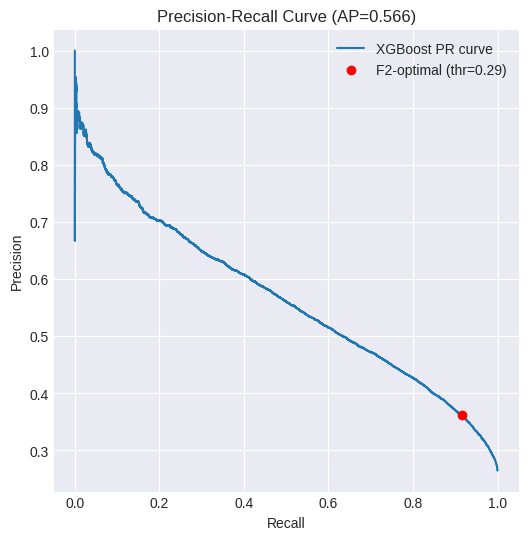

In [34]:
plt.figure(figsize=(6, 6))
plt.plot(recalls, precisions, label='XGBoost PR curve')
plt.scatter(recalls[best_idx], precisions[best_idx], color='red', zorder=5,
            label=f'F2-optimal (thr={best_threshold_f2:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AP={average_precision_score(y_test, xgb_probs):.3f})')
plt.legend()
plt.show()


## 10. Final evaluation at the tuned threshold

Threshold used: 0.294

              precision    recall  f1-score   support

    No Churn       0.93      0.42      0.58     44124
       Churn       0.36      0.92      0.52     15876

    accuracy                           0.55     60000
   macro avg       0.65      0.67      0.55     60000
weighted avg       0.78      0.55      0.56     60000



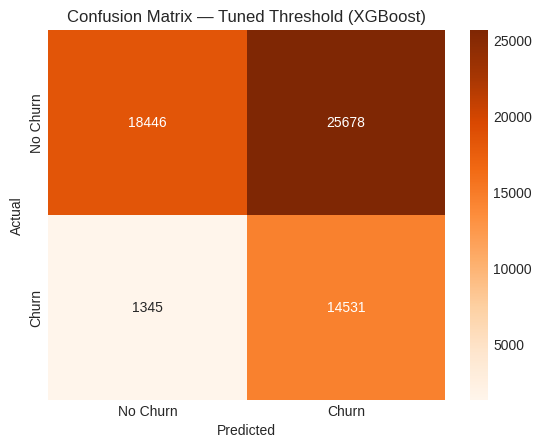

In [35]:
CHOSEN_THRESHOLD = best_threshold_f2   # swap for a value from recall_table if you want a stricter recall floor

final_preds = (xgb_probs >= CHOSEN_THRESHOLD).astype(int)

print(f"Threshold used: {CHOSEN_THRESHOLD:.3f}\n")
print(classification_report(y_test, final_preds, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, final_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Tuned Threshold (XGBoost)')
plt.show()


## 11. Feature importance (XGBoost)
Top churn drivers overall — a global view. (Student C's SHAP work gives the *per-customer* version of this for the retention emails.)

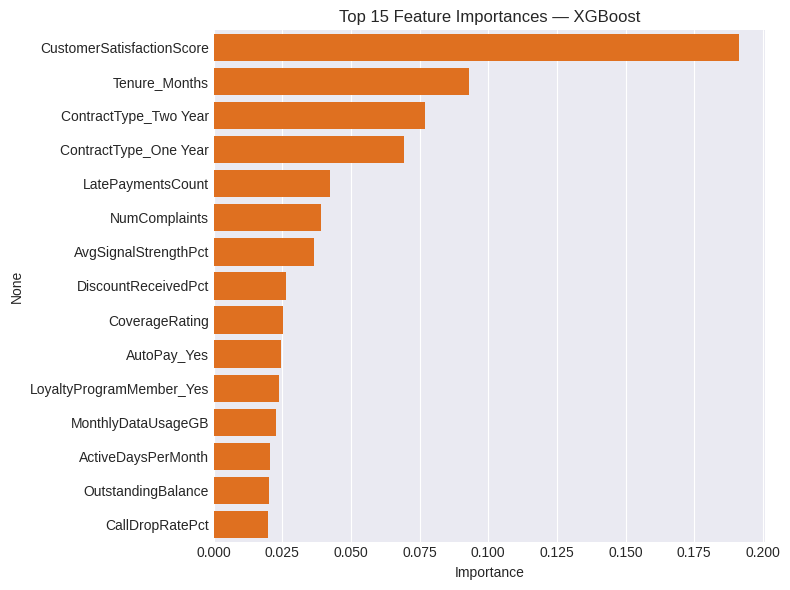

In [36]:
importances = pd.Series(xgb_clf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index, color='#ff6b00')
plt.title('Top 15 Feature Importances — XGBoost')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


## 12. Export model for the Churn Score API
Saves everything the FastAPI endpoint needs: the trained model, the scaler (in case a scaled model is preferred), the tuned threshold, and the exact column order used for encoding — so a new customer row can be encoded identically at inference time.

In [37]:
joblib.dump(xgb_clf, 'xgb_churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'model_columns.pkl')
joblib.dump(CHOSEN_THRESHOLD, 'churn_threshold.pkl')

print("Saved: xgb_churn_model.pkl, scaler.pkl, model_columns.pkl, churn_threshold.pkl")


Saved: xgb_churn_model.pkl, scaler.pkl, model_columns.pkl, churn_threshold.pkl


## 13. Inference helper (drop this into the FastAPI service)
Takes a raw customer dict (same schema as the original CSV, minus `Churn`), one-hot encodes it the same way, aligns columns to the training set, and returns a churn probability + flag.

In [38]:
def score_customer(raw_dict: dict) -> dict:
    """raw_dict: {column_name: value} for one customer, same schema as clean.csv (no 'Churn' key)."""
    model = joblib.load('xgb_churn_model.pkl')
    columns = joblib.load('model_columns.pkl')
    threshold = joblib.load('churn_threshold.pkl')

    row = pd.DataFrame([raw_dict])
    row_enc = pd.get_dummies(row)
    row_enc = row_enc.reindex(columns=columns, fill_value=0)

    prob = model.predict_proba(row_enc)[0, 1]
    return {'churn_probability': round(float(prob), 4), 'churn_flag': bool(prob >= threshold)}

example = df.drop(columns=['Churn']).iloc[0].to_dict()
score_customer(example)


{'churn_probability': 0.683, 'churn_flag': True}